In [42]:
!nvidia-smi

Wed Nov 25 09:29:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P0             29W /   70W |    5367MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [43]:
!pip -q install -U transformers datasets accelerate matplotlib triton

import torch, triton, transformers
print("torch", torch.__version__, "| triton", triton.__version__, "| transformers", transformers.__version__)
print(torch.cuda.get_device_name(0))
assert torch.cuda.is_available()

torch 2.14.1+cu130 | triton 3.8.0 | transformers 5.24.1
Tesla T4


In [44]:
import os, time, math, json, random
from collections import defaultdict, deque
import numpy as np
import torch
import torch.nn.functional as F

MODEL_NAME = "Qwen/Qwen2.5-0.5B"
SEQ_LEN = 512
FA1_BLOCK = 64
TRAIN_TOKENS = 1_000_000
EVAL_TOKENS = 100_000
MICRO_BS = 2
GRAD_ACCUM = 8
LR = 1e-5
WARMUP_STEPS = 10
LOG_EVERY = 5
SEED = 42
OUT_DIR = "/content/qwen05b_fa1_finetuned"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda"

FlashAttention-1 kernels in Triton, forward and backward

In [45]:
import triton
import triton.language as tl

@triton.jit
def _fa1_fwd_kernel(Q, K, V, O, M, L, CNT, sm_scale, N,
                    D: tl.constexpr, BR: tl.constexpr, BC: tl.constexpr,
                    CAUSAL: tl.constexpr, COUNT: tl.constexpr):
    bh   = tl.program_id(0)
    base = bh.to(tl.int64) * N * D
    vec  = bh.to(tl.int64) * N
    offs_d = tl.arange(0, D)
    offs_r = tl.arange(0, BR)
    offs_c = tl.arange(0, BC)
    Tc = N // BC
    Tr = N // BR
    for j in range(0, Tc):                                   # outer loop: K/V tiles
        cols = j * BC + offs_c
        kj = tl.load(K + base + cols[:, None] * D + offs_d[None, :])   # HBM -> SRAM
        vj = tl.load(V + base + cols[:, None] * D + offs_d[None, :])   # HBM -> SRAM
        if COUNT:
            tl.atomic_add(CNT + 0, 1)
        if CAUSAL:
            i_lo = (j * BC) // BR
        else:
            i_lo = 0
        for i in range(i_lo, Tr):                            # inner loop: Q/O tiles
            rows = i * BR + offs_r
            qi = tl.load(Q + base + rows[:, None] * D + offs_d[None, :])
            oi = tl.load(O + base + rows[:, None] * D + offs_d[None, :]).to(tl.float32)
            mi = tl.load(M + vec + rows)
            li = tl.load(L + vec + rows)
            if COUNT:
                tl.atomic_add(CNT + 1, 1)
            s = tl.dot(qi, tl.trans(kj)) * sm_scale
            if CAUSAL:
                s = tl.where(rows[:, None] >= cols[None, :], s, float("-inf"))
            m_t = tl.max(s, 1)
            p   = tl.exp(s - m_t[:, None])
            l_t = tl.sum(p, 1)
            m_new = tl.maximum(mi, m_t)
            a = tl.exp(mi - m_new)
            b = tl.exp(m_t - m_new)
            l_new = a * li + b * l_t
            pv = tl.dot(p.to(tl.float16), vj)
            o_new = ((li * a)[:, None] * oi + b[:, None] * pv) / l_new[:, None]
            tl.store(O + base + rows[:, None] * D + offs_d[None, :], o_new.to(tl.float16))
            tl.store(M + vec + rows, m_new)
            tl.store(L + vec + rows, l_new)

# Backward
@triton.jit
def _fa1_bwd_kernel(Q, K, V, DO, DQ, DK, DV, M, L, DELTA, CNT, sm_scale, N,
                    D: tl.constexpr, BR: tl.constexpr, BC: tl.constexpr,
                    CAUSAL: tl.constexpr, COUNT: tl.constexpr):
    bh   = tl.program_id(0)
    base = bh.to(tl.int64) * N * D
    vec  = bh.to(tl.int64) * N
    offs_d = tl.arange(0, D)
    offs_r = tl.arange(0, BR)
    offs_c = tl.arange(0, BC)
    Tc = N // BC
    Tr = N // BR
    for j in range(0, Tc):
        cols = j * BC + offs_c
        kj = tl.load(K + base + cols[:, None] * D + offs_d[None, :])   # HBM -> SRAM
        vj = tl.load(V + base + cols[:, None] * D + offs_d[None, :])   # HBM -> SRAM
        if COUNT:
            tl.atomic_add(CNT + 2, 1)
        dk = tl.zeros([BC, D], dtype=tl.float32)
        dv = tl.zeros([BC, D], dtype=tl.float32)
        if CAUSAL:
            i_lo = (j * BC) // BR
        else:
            i_lo = 0
        for i in range(i_lo, Tr):
            rows = i * BR + offs_r
            qi  = tl.load(Q  + base + rows[:, None] * D + offs_d[None, :])
            doi = tl.load(DO + base + rows[:, None] * D + offs_d[None, :])
            mi  = tl.load(M + vec + rows)
            li  = tl.load(L + vec + rows)
            di  = tl.load(DELTA + vec + rows)
            if COUNT:
                tl.atomic_add(CNT + 3, 1)
            s = tl.dot(qi, tl.trans(kj)) * sm_scale
            if CAUSAL:
                s = tl.where(rows[:, None] >= cols[None, :], s, float("-inf"))
            p  = tl.exp(s - mi[:, None]) / li[:, None]
            p16 = p.to(tl.float16)
            dv += tl.dot(tl.trans(p16), doi)
            dp = tl.dot(doi, tl.trans(vj))
            ds = (p * (dp - di[:, None]) * sm_scale).to(tl.float16)
            dk += tl.dot(tl.trans(ds), qi)
            dq_old = tl.load(DQ + base + rows[:, None] * D + offs_d[None, :])
            dq_new = dq_old + tl.dot(ds, kj)
            tl.store(DQ + base + rows[:, None] * D + offs_d[None, :], dq_new)
        tl.store(DK + base + cols[:, None] * D + offs_d[None, :], dk.to(tl.float16))
        tl.store(DV + base + cols[:, None] * D + offs_d[None, :], dv.to(tl.float16))


def fa1_forward(q, k, v, sm_scale, block, cnt=None):
    BH, N, D = q.shape
    o = torch.zeros_like(q)
    m = torch.full((BH, N), float("-inf"), device=q.device, dtype=torch.float32)
    l = torch.zeros((BH, N), device=q.device, dtype=torch.float32)
    dummy = cnt if cnt is not None else torch.zeros(8, dtype=torch.int32, device=q.device)
    _fa1_fwd_kernel[(BH,)](q, k, v, o, m, l, dummy, sm_scale, N,
                           D=D, BR=block, BC=block, CAUSAL=True, COUNT=cnt is not None,
                           num_warps=4, num_stages=1)
    return o, m, l


def fa1_backward(q, k, v, o, m, l, do, sm_scale, block, cnt=None):
    BH, N, D = q.shape
    delta = (do.float() * o.float()).sum(-1).contiguous()
    dq = torch.zeros(q.shape, device=q.device, dtype=torch.float32)
    dk = torch.empty_like(k); dv = torch.empty_like(v)
    dummy = cnt if cnt is not None else torch.zeros(8, dtype=torch.int32, device=q.device)
    _fa1_bwd_kernel[(BH,)](q, k, v, do, dq, dk, dv, m, l, delta, dummy, sm_scale, N,
                           D=D, BR=block, BC=block, CAUSAL=True, COUNT=cnt is not None,
                           num_warps=4, num_stages=1)
    return dq.to(q.dtype), dk, dv


class FA1Func(torch.autograd.Function):
    @staticmethod
    @torch.amp.custom_fwd(device_type="cuda", cast_inputs=torch.float16)
    def forward(ctx, q, k, v, sm_scale, layer_idx):
        B, H, N, D = q.shape
        assert N % FA1_BLOCK == 0, "SEQ_LEN must be a multiple of FA1_BLOCK"
        qf = q.reshape(B * H, N, D).contiguous()
        kf = k.reshape(B * H, N, D).contiguous()
        vf = v.reshape(B * H, N, D).contiguous()
        o, m, l = fa1_forward(qf, kf, vf, sm_scale, FA1_BLOCK)
        ctx.save_for_backward(qf, kf, vf, o, m, l)
        ctx.meta = (B, H, N, D, sm_scale, layer_idx)
        TRAFFIC.record("fwd", layer_idx, B * H, N, D)
        return o.view(B, H, N, D)

    @staticmethod
    @torch.amp.custom_bwd(device_type="cuda")
    def backward(ctx, do):
        qf, kf, vf, o, m, l = ctx.saved_tensors
        B, H, N, D, sm_scale, layer_idx = ctx.meta
        do = do.reshape(B * H, N, D).to(torch.float16).contiguous()
        dq, dk, dv = fa1_backward(qf, kf, vf, o, m, l, do, sm_scale, FA1_BLOCK)
        TRAFFIC.record("bwd", layer_idx, B * H, N, D)
        return dq.view(B, H, N, D), dk.view(B, H, N, D), dv.view(B, H, N, D), None, None

FA1 schedule for ONE (batch, head): N=512, block=64, d=64, tiles=8
outer j=0: HBM->SRAM  K[0] + V[0]  (16 KiB)
    inner i=0: HBM->SRAM Q[0],O[0],m,l -> compute -> SRAM->HBM O[0],m,l
    inner i=1: HBM->SRAM Q[1],O[1],m,l -> compute -> SRAM->HBM O[1],m,l
    inner i=2: HBM->SRAM Q[2],O[2],m,l -> compute -> SRAM->HBM O[2],m,l
    inner i=3: HBM->SRAM Q[3],O[3],m,l -> compute -> SRAM->HBM O[3],m,l
    inner i=4: HBM->SRAM Q[4],O[4],m,l -> compute -> SRAM->HBM O[4],m,l
    inner i=5: HBM->SRAM Q[5],O[5],m,l -> compute -> SRAM->HBM O[5],m,l
    inner i=6: HBM->SRAM Q[6],O[6],m,l -> compute -> SRAM->HBM O[6],m,l
    inner i=7: HBM->SRAM Q[7],O[7],m,l -> compute -> SRAM->HBM O[7],m,l
outer j=1: HBM->SRAM  K[1] + V[1]  (16 KiB)
    inner i=1: HBM->SRAM Q[1],O[1],m,l -> compute -> SRAM->HBM O[1],m,l
    inner i=2: HBM->SRAM Q[2],O[2],m,l -> compute -> SRAM->HBM O[2],m,l
    inner i=3: HBM->SRAM Q[3],O[3],m,l -> compute -> SRAM->HBM O[3],m,l
    inner i=4: HBM->SRAM Q[4],O[4],m,l -> compute -> 

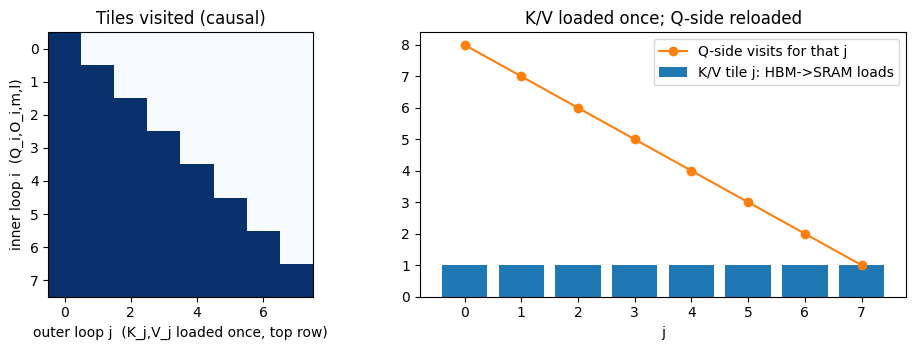

In [46]:
import matplotlib.pyplot as plt

def schedule(N, block, causal=True):
    """Exact tile schedule of the kernels above (per batch*head)."""
    T = N // block
    kv_loads = T                                                  # each K/V tile pair loaded once
    inner = sum(T - (j if causal else 0) for j in range(T))       # Q/O/m/l tile visits
    return kv_loads, inner

class Traffic:
    def __init__(self):
        self.enabled = True
        self.total = defaultdict(float)
        self.step = defaultdict(float)
        self.events = deque(maxlen=8)
    def begin_step(self):
        self.step = defaultdict(float)
    def record(self, phase, layer, BH, N, D, block=None, causal=True):
        if not self.enabled:
            return
        block = block or FA1_BLOCK
        kv_loads, inner = schedule(N, block, causal)
        tile  = block * D * 2                                    # one fp16 K or V tile
        kv_tiles = BH * kv_loads                                 # K/V tile *pairs* loaded
        kv_bytes = kv_tiles * 2 * tile
        if phase == "fwd":
            q_rd = BH * inner * (2 * tile + 2 * block * 4)       # Q,O (fp16) + m,l (fp32)
            q_wr = BH * inner * (tile + 2 * block * 4)
        else:
            q_rd = BH * inner * (2 * tile + 3 * block * 4 + block * D * 4)  # Q,dO + m,l,delta + dQ fp32
            q_wr = BH * inner * (block * D * 4) + kv_tiles * 2 * tile        # dQ + dK,dV
        logical = BH * N * D * 2 * 2                             # K+V bytes if read exactly once
        for d in (self.step, self.total):
            d[f"{phase}_calls"]     += 1
            d[f"{phase}_kv_tiles"]  += kv_tiles
            d[f"{phase}_kv_bytes"]  += kv_bytes
            d[f"{phase}_kv_logical"] += logical
            d[f"{phase}_other_rd"]  += q_rd
            d[f"{phase}_other_wr"]  += q_wr
        self.events.append((phase, layer, BH, kv_tiles, kv_bytes / 2**20))

TRAFFIC = Traffic()

def describe_head_schedule(N=SEQ_LEN, block=None, D=64, causal=True, max_events=14):
    block = block or FA1_BLOCK
    T = N // block; tile = block * D * 2
    lines = []
    for j in range(T):
        lines.append(f"outer j={j}: HBM->SRAM  K[{j}] + V[{j}]  ({2*tile/1024:.0f} KiB)")
        for i in range(j if causal else 0, T):
            lines.append(f"    inner i={i}: HBM->SRAM Q[{i}],O[{i}],m,l -> compute -> SRAM->HBM O[{i}],m,l")
    print(f"FA1 schedule for ONE (batch, head): N={N}, block={block}, d={D}, tiles={T}")
    print("\n".join(lines[:max_events]))
    print(f"... {len(lines)} events total | K/V tile loads = {T} (each K/V tile loaded exactly once per pass)")
    vis = np.zeros((T, T))
    for j in range(T):
        for i in range(j if causal else 0, T):
            vis[i, j] = 1
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].imshow(vis, cmap="Blues", origin="upper")
    ax[0].set_xlabel("outer loop j  (K_j,V_j loaded once, top row)")
    ax[0].set_ylabel("inner loop i  (Q_i,O_i,m,l)")
    ax[0].set_title("Tiles visited (causal)")
    ax[1].bar(range(T), [1] * T, label="K/V tile j: HBM->SRAM loads")
    ax[1].plot(range(T), [T - j for j in range(T)], "o-", color="C1", label="Q-side visits for that j")
    ax[1].set_xlabel("j"); ax[1].legend(); ax[1].set_title("K/V loaded once; Q-side reloaded")
    plt.tight_layout(); plt.show()

describe_head_schedule()

In [47]:
def run_validation(block):
    global FA1_BLOCK
    FA1_BLOCK = block
    torch.manual_seed(0)
    B, H, N, D = 2, 3, 256, 64
    q = torch.randn(B, H, N, D, device=DEV, dtype=torch.float16, requires_grad=True)
    k = torch.randn(B, H, N, D, device=DEV, dtype=torch.float16, requires_grad=True)
    v = torch.randn(B, H, N, D, device=DEV, dtype=torch.float16, requires_grad=True)
    sm = D ** -0.5
    # reference in fp32
    qr, kr, vr = [t.detach().float().requires_grad_() for t in (q, k, v)]
    ref = F.scaled_dot_product_attention(qr, kr, vr, is_causal=True)
    g = torch.randn_like(ref)
    ref.backward(g)
    # FA1 kernels
    TRAFFIC.enabled = False
    out = FA1Func.apply(q, k, v, sm, 0)
    out.backward(g.half())
    TRAFFIC.enabled = True
    print(f"[block={block}] max err  out={(out.float()-ref).abs().max():.4f}  "
          f"dq={(q.grad.float()-qr.grad).abs().max():.4f}  "
          f"dk={(k.grad.float()-kr.grad).abs().max():.4f}  "
          f"dv={(v.grad.float()-vr.grad).abs().max():.4f}")
    # counter check: debug build with atomic counters (NOT used in training)
    BH = B * H
    qf, kf, vf = [t.detach().reshape(BH, N, D).contiguous() for t in (q, k, v)]
    cnt = torch.zeros(8, dtype=torch.int32, device=DEV)
    o, m, l = fa1_forward(qf, kf, vf, sm, block, cnt=cnt)
    fa1_backward(qf, kf, vf, o, m, l, g.half().reshape(BH, N, D).contiguous(), sm, block, cnt=cnt)
    torch.cuda.synchronize()
    kv_loads, inner = schedule(N, block)
    exp = [BH * kv_loads, BH * inner, BH * kv_loads, BH * inner]
    got = cnt[:4].tolist()
    print(f"[block={block}] measured in-kernel [fwd K/V, fwd Q-side, bwd K/V, bwd Q-side] = {got}")
    print(f"[block={block}] analytic schedule                                             = {exp}")
    assert got == exp, "analytic schedule does not match the kernel"
    print("OK: K/V tile-load counts match the kernel exactly.")

for blk in (64, 32):
    try:
        run_validation(blk)
        break
    except Exception as e:
        print(f"block={blk} failed: {type(e).__name__}: {str(e)[:200]}")
        if blk == 32:
            raise
print("Using FA1_BLOCK =", FA1_BLOCK)

block=64 failed: OutOfResources: out of resource: shared memory, Required: 81920, Hardware limit: 65536. Reducing block sizes or `num_stages` may help.
[block=32] max err  out=0.0010  dq=0.0012  dk=0.0013  dv=0.0016
[block=32] measured in-kernel [fwd K/V, fwd Q-side, bwd K/V, bwd Q-side] = [48, 216, 48, 216]
[block=32] analytic schedule                                             = [48, 216, 48, 216]
OK: K/V tile-load counts match the kernel exactly.
Using FA1_BLOCK = 32


In [48]:
from datasets import load_dataset
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
ds  = load_dataset("HuggingFaceFW/fineweb-edu", name="sample-10BT", split="train", streaming=True)
it  = iter(ds)

def take_tokens(n_tokens, batch_docs=64):
    ids, total = [], 0
    while total < n_tokens:
        texts = [next(it)["text"] for _ in range(batch_docs)]
        for t in tok(texts, add_special_tokens=False)["input_ids"]:
            t = t + [tok.eos_token_id]
            ids.extend(t); total += len(t)
    return ids[:n_tokens]

def pack(ids):
    n = len(ids) // SEQ_LEN
    return torch.tensor(ids[:n * SEQ_LEN], dtype=torch.long).view(n, SEQ_LEN)

t0 = time.time()
eval_data  = pack(take_tokens(EVAL_TOKENS))
train_data = pack(take_tokens(TRAIN_TOKENS))
print(f"train seqs: {len(train_data)} ({train_data.numel():,} tokens) | eval seqs: {len(eval_data)} | {time.time()-t0:.0f}s")

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

train seqs: 1953 (999,936 tokens) | eval seqs: 195 | 12s


In [54]:
from transformers import AutoModelForCausalLM, AttentionInterface
from transformers.models.qwen2.modeling_qwen2 import repeat_kv

def fa1_attention(module, query, key, value, attention_mask, dropout=0.0,
                  scaling=None, sliding_window=None, **kwargs):
    # query: [B, H, N, D]; key/value: [B, H_kv, N, D]. Qwen2.5-0.5B uses GQA, so K/V are expanded to H heads.
    key   = repeat_kv(key,   module.num_key_value_groups)
    value = repeat_kv(value, module.num_key_value_groups)
    scaling = scaling if scaling is not None else module.head_dim ** -0.5
    out = FA1Func.apply(query, key, value, scaling, module.layer_idx)   # causal, no padding (packed data)
    return out.transpose(1, 2).contiguous(), None

AttentionInterface.register("fa1_triton", fa1_attention)
try:
    from transformers.masking_utils import AttentionMaskInterface, sdpa_mask
    AttentionMaskInterface.register("fa1_triton", sdpa_mask)   # mask is ignored by our kernel (always causal)
except Exception as e:
    print("mask registration skipped:", e)

# Load the model in half-precision (float16) to prevent CUDA OOM on the Tesla T4 GPU
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, torch_dtype=torch.float16, attn_implementation="fa1_triton").to(DEVICE)
model.config.use_cache = False
print("attention impl:", model.config._attn_implementation,
      "| params: %.3fB" % (sum(p.numel() for p in model.parameters()) / 1e9))

# sanity: one forward must hit our kernel once per layer
TRAFFIC.enabled = True; TRAFFIC.begin_step(); TRAFFIC.total.clear()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    model(input_ids=train_data[:1].to(DEVICE))
print("FA1 forward calls in one model forward:", int(TRAFFIC.step["fwd_calls"]),
      "(expected", model.config.num_hidden_layers, ")")
TRAFFIC.total.clear(); TRAFFIC.begin_step()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

attention impl: fa1_triton | params: 0.494B
FA1 forward calls in one model forward: 24 (expected 24 )


In [50]:
from IPython.display import clear_output

@torch.no_grad()
def evaluate(model, data, bs=4):
    model.eval(); TRAFFIC.enabled = False
    tot_loss, tot_tok = 0.0, 0
    for i in range(0, len(data), bs):
        x = data[i:i + bs].to(DEV)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(input_ids=x).logits
        loss = F.cross_entropy(logits[:, :-1].float().reshape(-1, logits.size(-1)),
                               x[:, 1:].reshape(-1), reduction="sum")
        tot_loss += loss.item(); tot_tok += x[:, 1:].numel()
    TRAFFIC.enabled = True; model.train()
    return tot_loss / tot_tok, math.exp(tot_loss / tot_tok)

MiB, GiB = 2**20, 2**30

def kv_panel(history):
    clear_output(wait=True)
    s = TRAFFIC.step
    print("=" * 84)
    print(f"K/V transfers HBM -> SRAM | FlashAttention-1 | Br=Bc={FA1_BLOCK} | N={SEQ_LEN} | d=64")
    print("=" * 84)
    for ph, name in (("fwd", "forward "), ("bwd", "backward")):
        calls = int(s[f"{ph}_calls"])
        if calls:
            print(f"{name}: {calls:4d} kernel calls | K/V tile-pair loads {int(s[f'{ph}_kv_tiles']):>9,} "
                  f"| K/V {s[f'{ph}_kv_bytes']/GiB:7.3f} GiB "
                  f"| loads per K/V element = {s[f'{ph}_kv_bytes']/s[f'{ph}_kv_logical']:.2f}x "
                  f"| Q/O/m/l side {(s[f'{ph}_other_rd']+s[f'{ph}_other_wr'])/GiB:7.3f} GiB")
    print(f"this step total K/V HBM->SRAM : {(s['fwd_kv_bytes']+s['bwd_kv_bytes'])/GiB:.3f} GiB"
          f"   | cumulative: {(TRAFFIC.total['fwd_kv_bytes']+TRAFFIC.total['bwd_kv_bytes'])/GiB:.2f} GiB")
    print("last kernel calls (phase, layer, heads, K/V tile pairs, K/V MiB):")
    for e in list(TRAFFIC.events)[-6:]:
        print(f"   {e[0]} layer {e[1]:>2} heads {e[2]:>3} tiles {e[3]:>5} K/V {e[4]:7.2f} MiB")
    print("-" * 84)
    print(f"{'step':>5} {'loss':>8} {'lr':>9} {'s/step':>7} {'tok/s':>8} {'peakGB':>7} {'K/V GiB/step':>13}")
    for h in history[-10:]:
        print(f"{h['step']:>5} {h['loss']:>8.4f} {h['lr']:>9.2e} {h['sec']:>7.2f} {h['tok_s']:>8.0f} "
              f"{h['peak_gb']:>7.2f} {h['kv_gib']:>13.3f}")

K/V transfers HBM -> SRAM | FlashAttention-1 | Br=Bc=32 | N=512 | d=64
forward :  192 kernel calls | K/V tile-pair loads    86,016 | K/V   0.656 GiB | loads per K/V element = 1.00x | Q/O/m/l side   8.716 GiB
backward:  192 kernel calls | K/V tile-pair loads    86,016 | K/V   0.656 GiB | loads per K/V element = 1.00x | Q/O/m/l side  17.652 GiB
this step total K/V HBM->SRAM : 1.312 GiB   | cumulative: 160.12 GiB
last kernel calls (phase, layer, heads, K/V tile pairs, K/V MiB):
   bwd layer  5 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  4 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  3 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  2 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  1 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  0 heads  28 tiles   448 K/V    3.50 MiB
------------------------------------------------------------------------------------
 step     loss        lr  s/step    tok/s  peakGB  K/V GiB/step
  113   2.7027  1.18e-06    3.12     2626   13.

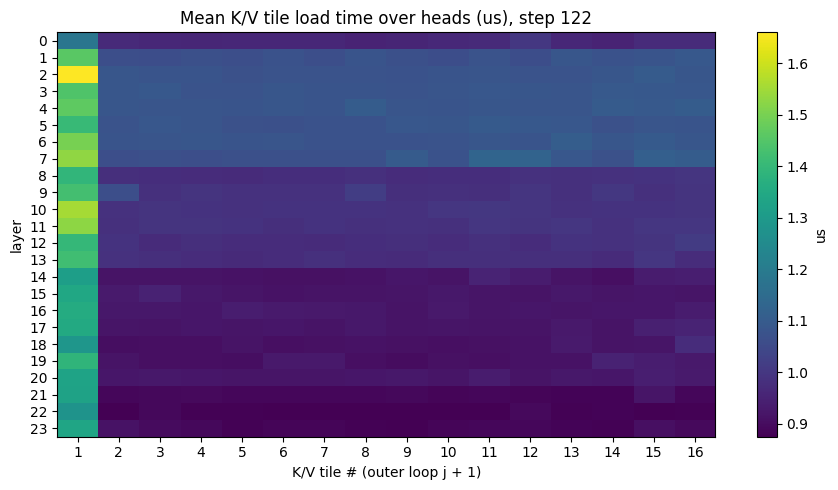

In [59]:
import gc, csv
from transformers import AutoModelForCausalLM
gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

assert "timed_forward" in globals(), "Run Cell 7b first: it defines the timed K/V tile kernel."

# ---------------- options ----------------
PROFILE_LAYERS        = "all"   # "all" or a list such as [0, 12, 23]
PRINT_EVERY_TILE_LINE = False   # True: also print one serial line per (layer, head, tile)
TILE_CSV              = "/content/kv_tile_times.csv"
MAX_SANE_LOSS         = 8.0     # random guessing is ~11.9; healthy Qwen2.5-0.5B on web text is ~2.5-3.5
# -----------------------------------------

# ---- 1) fp32 master weights (reload from the checkpoint, not model.float()) ----
def load_fp32():
    kw = dict(attn_implementation="fa1_triton")
    try:
        m = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32, **kw)
    except TypeError:
        m = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32, **kw)
    m.config.use_cache = False
    return m.to(DEVICE)

dtypes = {str(p.dtype) for p in model.parameters()}
print("parameter dtypes:", dtypes)
if dtypes != {"torch.float32"}:
    print("-> not fp32; reloading Qwen2.5-0.5B in fp32")
    del model; gc.collect(); torch.cuda.empty_cache()
    model = load_fp32()
    print("parameter dtypes now:", {str(p.dtype) for p in model.parameters()})
model.config._attn_implementation = "fa1_triton"

# ---- 2) preflight: same batch through SDPA and through the FA1 kernel ----
def quick_loss(impl, x):
    model.config._attn_implementation = impl
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        return model(input_ids=x, labels=x).loss.item()

model.eval(); TRAFFIC.enabled = False
xb = eval_data[:2].to(DEVICE)
loss_sdpa = quick_loss("sdpa", xb)
loss_fa1  = quick_loss("fa1_triton", xb)
model.config._attn_implementation = "fa1_triton"
TRAFFIC.enabled = True; TRAFFIC.total.clear(); TRAFFIC.begin_step(); model.train()
print(f"preflight loss  SDPA: {loss_sdpa:.3f}   FA1 kernel: {loss_fa1:.3f}")
if not (loss_sdpa < MAX_SANE_LOSS and loss_fa1 < MAX_SANE_LOSS):
    if loss_sdpa < MAX_SANE_LOSS:
        why = "SDPA is healthy but the FA1 kernel is not: the kernel is wrong on real Qwen activations."
    else:
        why = "Even SDPA is broken: the weights or fp16 activations are the problem, not the FA1 kernel."
    raise RuntimeError(f"Stopping before training. {why} Send me the two losses above.")

# ---- 3) K/V tile profiler: all layers, all heads (separate timed pass, training kernels untouched) ----
N_LAYERS = model.config.num_hidden_layers
LAYERS = list(range(N_LAYERS)) if PROFILE_LAYERS == "all" else list(PROFILE_LAYERS)

def profile_kv_tiles(x_one, layers):
    captured = {}
    wanted = set(layers)
    def capturing(module, query, key, value, attention_mask, **kwargs):
        if module.layer_idx in wanted and module.layer_idx not in captured:
            scale = kwargs.get("scaling") or module.head_dim ** -0.5
            captured[module.layer_idx] = (
                query.detach().to(torch.float16).squeeze(0).contiguous(),
                repeat_kv(key,   module.num_key_value_groups).detach().to(torch.float16).squeeze(0).contiguous(),
                repeat_kv(value, module.num_key_value_groups).detach().to(torch.float16).squeeze(0).contiguous(),
                scale)
        return fa1_attention(module, query, key, value, attention_mask, **kwargs)
    prev = TRAFFIC.enabled
    AttentionInterface.register("fa1_triton", capturing)
    TRAFFIC.enabled = False
    try:
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            model(input_ids=x_one)
    finally:
        AttentionInterface.register("fa1_triton", fa1_attention)   # back to the normal kernel path
        TRAFFIC.enabled = prev
    out = {}
    for layer in layers:
        q, k, v, scale = captured[layer]                              # q: [H, N, D] (one sequence)
        log, prog = timed_forward(q, k, v, scale, FA1_BLOCK)
        out[layer] = (log, prog, q.shape[-1])
    return out

def show_all_heads_timing(layer, log, prog, block, D, every_line=False):
    """Print K/V tile load time for EVERY head of one layer; returns seconds array [heads, tiles]."""
    cycles = (prog[:, 1] - prog[:, 0]).double()
    nanos  = (prog[:, 3] - prog[:, 2]).double()
    ghz    = (cycles.sum() / nanos.sum()).item()                     # effective clock, cycles per ns
    sec    = (log[:, :, 0].double() / ghz * 1e-9).cpu().numpy()      # [heads, tiles] seconds
    BH, TC = sec.shape
    tile_b = 2 * block * D * 2                                       # K tile + V tile, fp16
    print("=" * (14 + 7 * TC + 16))
    print(f"Layer {layer:02d} | K/V tile HBM->SRAM time per head (us; seconds = us x 1e-6) | "
          f"{tile_b/1024:.0f} KiB per tile pair | clock {ghz:.2f} GHz")
    print(f"head | " + " ".join(f"{t+1:>6}" for t in range(TC)) + " |  total (s)")
    for h in range(BH):
        print(f"H{h:02d}  | " + " ".join(f"{sec[h, t]*1e6:6.2f}" for t in range(TC)) + f" | {sec[h].sum():.9f}")
    print(f"mean | " + " ".join(f"{sec[:, t].mean()*1e6:6.2f}" for t in range(TC)) +
          f" | {sec.sum(1).mean():.9f}   (avg {tile_b/sec.mean()/1e9:.1f} GB/s per tile pair)")
    if every_line:
        for h in range(BH):
            for t in range(TC):
                print(f"L{layer:02d} H{h:02d} tile {t+1:>2}. K_{t},V_{t}  {tile_b/1024:.0f}Ki  {sec[h, t]:.9f} s")
    return sec

# ---- 4) baseline eval, optimizer, scaler ----
base_loss, base_ppl = evaluate(model, eval_data)
print(f"BEFORE fine-tuning: eval loss {base_loss:.4f} | ppl {base_ppl:.2f}")

model.train()
opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.01, fused=True)
scaler = torch.amp.GradScaler("cuda")
seqs_per_step = MICRO_BS * GRAD_ACCUM
total_steps   = len(train_data) // seqs_per_step
def lr_at(step):
    if step < WARMUP_STEPS: return LR * (step + 1) / WARMUP_STEPS
    p = (step - WARMUP_STEPS) / max(1, total_steps - WARMUP_STEPS)
    return LR * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * p)))

torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
TRAFFIC.total.clear()
perm = torch.randperm(len(train_data))
history, tile_log = [], []
profile_seconds = 0.0
train_start = time.time()

for step in range(total_steps):
    t0 = time.time(); TRAFFIC.begin_step()
    for g in opt.param_groups:
        g["lr"] = lr_at(step)
    step_loss = 0.0
    for micro in range(GRAD_ACCUM):
        a = (step * GRAD_ACCUM + micro) * MICRO_BS
        x = train_data[perm[a:a + MICRO_BS]].to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = model(input_ids=x, labels=x).loss / GRAD_ACCUM
        scaler.scale(loss).backward()
        step_loss += loss.item()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    torch.cuda.synchronize()
    dt = time.time() - t0
    history.append(dict(step=step + 1, loss=step_loss, lr=lr_at(step), sec=dt,
                        tok_s=seqs_per_step * SEQ_LEN / dt,
                        peak_gb=torch.cuda.max_memory_allocated() / GiB,
                        kv_gib=(TRAFFIC.step["fwd_kv_bytes"] + TRAFFIC.step["bwd_kv_bytes"]) / GiB,
                        fwd_kv_gib=TRAFFIC.step["fwd_kv_bytes"] / GiB,
                        bwd_kv_gib=TRAFFIC.step["bwd_kv_bytes"] / GiB))
    if (step + 1) % LOG_EVERY == 0 or step == 0 or step + 1 == total_steps:
        kv_panel(history)
        tp0 = time.time()
        prof = profile_kv_tiles(x[:1], LAYERS)
        print(f"\nStep {step + 1}: serial K/V tile transfer time HBM -> SRAM | forward kernel | "
              f"{len(LAYERS)} layers x all heads | real q/k/v from this step")
        for layer, (log, prog, D) in prof.items():
            sec = show_all_heads_timing(layer, log, prog, FA1_BLOCK, D, every_line=PRINT_EVERY_TILE_LINE)
            tile_log.append(dict(step=step + 1, layer=layer, sec=sec.tolist()))
        profile_seconds += time.time() - tp0

train_seconds = time.time() - train_start - profile_seconds
print(f"\nTraining done: {total_steps} steps in {train_seconds/60:.1f} min "
      f"(+{profile_seconds/60:.1f} min of K/V timing passes) | peak GPU mem {torch.cuda.max_memory_allocated()/GiB:.2f} GiB")

# ---- 5) save every number and show a layers x tiles heatmap (latest profile) ----
with open(TILE_CSV, "w", newline="") as f:
    w = csv.writer(f); w.writerow(["step", "layer", "head", "tile", "seconds"])
    for r in tile_log:
        for h, row in enumerate(r["sec"]):
            for t, s in enumerate(row):
                w.writerow([r["step"], r["layer"], h, t, f"{s:.9f}"])
print("saved all per-tile timings to", TILE_CSV)

last_step = tile_log[-1]["step"]
grid = np.array([np.mean(r["sec"], axis=0) * 1e6 for r in tile_log if r["step"] == last_step])  # [layers, tiles] us
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(grid, aspect="auto", cmap="viridis")
ax.set_xlabel("K/V tile # (outer loop j + 1)"); ax.set_ylabel("layer")
ax.set_yticks(range(len(LAYERS))); ax.set_yticklabels(LAYERS)
ax.set_xticks(range(grid.shape[1])); ax.set_xticklabels(range(1, grid.shape[1] + 1))
ax.set_title(f"Mean K/V tile load time over heads (us), step {last_step}")
plt.colorbar(im, label="us"); plt.tight_layout(); plt.show()

In [60]:
after_loss, after_ppl = evaluate(model, eval_data)
print(f"AFTER  fine-tuning: eval loss {after_loss:.4f} | ppl {after_ppl:.2f}")
print(f"BEFORE fine-tuning: eval loss {base_loss:.4f} | ppl {base_ppl:.2f}")

model.config._attn_implementation = "sdpa"      # so the saved checkpoint loads without our custom kernel
os.makedirs(OUT_DIR, exist_ok=True)
model.save_pretrained(OUT_DIR); tok.save_pretrained(OUT_DIR)
print("saved to", OUT_DIR)

AFTER  fine-tuning: eval loss 2.7448 | ppl 15.56
BEFORE fine-tuning: eval loss 2.7380 | ppl 15.46


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to /content/qwen05b_fa1_finetuned


{
  "steps": 122,
  "train_minutes": 6.342803378899892,
  "tokens_per_sec_avg": 2626.9207100024137,
  "peak_gpu_gib": 13.598427772521973,
  "eval_loss_before": 2.738011304878412,
  "eval_loss_after": 2.7447591831862486,
  "ppl_before": 15.456216809142541,
  "ppl_after": 15.560866162731214,
  "fa1_block": 32,
  "seq_len": 512,
  "kv_fwd_gib_total": 80.0625,
  "kv_bwd_gib_total": 80.0625,
  "kv_fwd_tile_pairs_total": 10493952,
  "kv_bwd_tile_pairs_total": 10493952
}


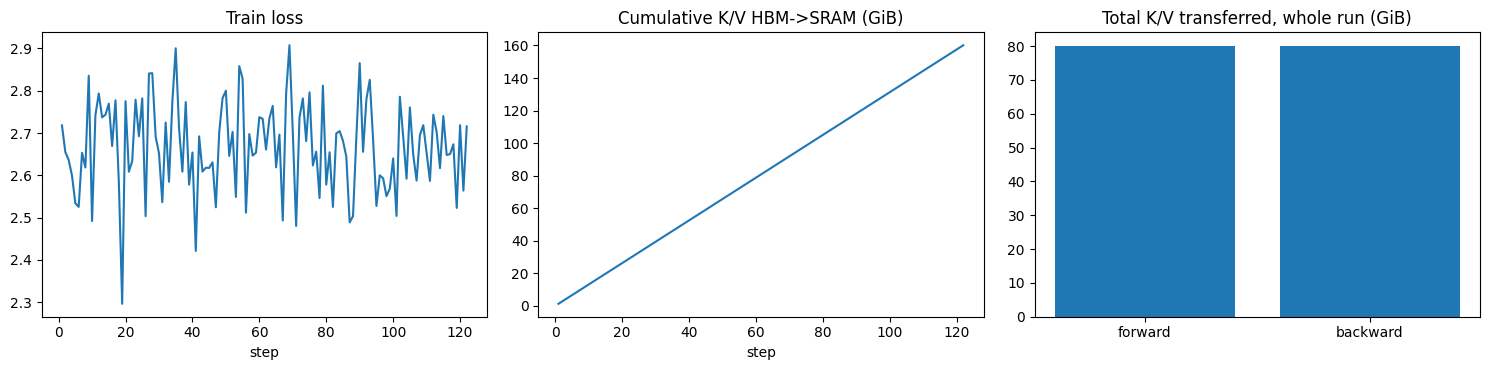

In [61]:
tot = TRAFFIC.total
summary = dict(
    steps=total_steps, train_minutes=train_seconds / 60,
    tokens_per_sec_avg=float(np.mean([h["tok_s"] for h in history])),
    peak_gpu_gib=torch.cuda.max_memory_allocated() / GiB,
    eval_loss_before=base_loss, eval_loss_after=after_loss, ppl_before=base_ppl, ppl_after=after_ppl,
    fa1_block=FA1_BLOCK, seq_len=SEQ_LEN,
    kv_fwd_gib_total=tot["fwd_kv_bytes"] / GiB, kv_bwd_gib_total=tot["bwd_kv_bytes"] / GiB,
    kv_fwd_tile_pairs_total=int(tot["fwd_kv_tiles"]), kv_bwd_tile_pairs_total=int(tot["bwd_kv_tiles"]),
)
print(json.dumps(summary, indent=2))
json.dump(dict(summary=summary, history=history), open(f"{OUT_DIR}/metrics.json", "w"), indent=2)

steps = [h["step"] for h in history]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(steps, [h["loss"] for h in history]); ax[0].set_title("Train loss"); ax[0].set_xlabel("step")
ax[1].plot(steps, np.cumsum([h["kv_gib"] for h in history]))
ax[1].set_title("Cumulative K/V HBM->SRAM (GiB)"); ax[1].set_xlabel("step")
ax[2].bar(["forward", "backward"], [tot["fwd_kv_bytes"] / GiB, tot["bwd_kv_bytes"] / GiB])
ax[2].set_title("Total K/V transferred, whole run (GiB)")
plt.tight_layout(); plt.show()

In [62]:
import os, shutil, torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from google.colab import files

# ---------------- options ----------------
EXPORT_DIR      = "/content/qwen05b_export"
SAVE_DTYPE      = torch.float16   # fp16 ~1 GB (good for serving); use torch.float32 for ~2 GB full precision
SAVE_TRAIN_STATE = False          # True also saves optimizer + scaler (~4 GB extra) so you can resume training later
COPY_TO_DRIVE   = False           # True copies the zip to Google Drive (more reliable than browser download for big files)
DRIVE_DIR       = "/content/drive/MyDrive/qwen05b_finetuned"
# -----------------------------------------

shutil.rmtree(EXPORT_DIR, ignore_errors=True)
os.makedirs(EXPORT_DIR, exist_ok=True)

# 1) Make the saved config load anywhere (no custom FA1 kernel needed to use the model)
model.config._attn_implementation = "sdpa"
model.config.use_cache = True

# 2) Cast a copy of the weights to the export dtype (training model stays fp32 in memory)
state = {k: v.detach().to("cpu", SAVE_DTYPE).contiguous() for k, v in model.state_dict().items()}

# 3a) .safetensors (+ config.json, generation_config.json)
model.save_pretrained(EXPORT_DIR, state_dict=state, safe_serialization=True)   # -> model.safetensors

# 3b) .bin (PyTorch pickle format)
torch.save(state, os.path.join(EXPORT_DIR, "pytorch_model.bin"))

# 3c) tokenizer files
tok.save_pretrained(EXPORT_DIR)

# 3d) optional: everything needed to keep training later
if SAVE_TRAIN_STATE:
    torch.save({"optimizer": opt.state_dict(), "scaler": scaler.state_dict(),
                "steps_done": len(history)}, os.path.join(EXPORT_DIR, "train_state.pt"))

# 4) Verify the saved safetensors file reloads and generates text
del state
test = AutoModelForCausalLM.from_pretrained(EXPORT_DIR, torch_dtype=SAVE_DTYPE).to("cuda").eval()
prompt = "Photosynthesis is the process by which"
ids = tok(prompt, return_tensors="pt").to("cuda")
with torch.no_grad():
    out = test.generate(**ids, max_new_tokens=40, do_sample=False)
print(tok.decode(out[0], skip_special_tokens=True))
del test; torch.cuda.empty_cache()

for f in sorted(os.listdir(EXPORT_DIR)):
    print(f"{f:32s} {os.path.getsize(os.path.join(EXPORT_DIR, f))/2**20:9.1f} MiB")

# 5) Zip and download
zip_path = shutil.make_archive("/content/qwen05b_finetuned", "zip", EXPORT_DIR)
print("zip:", zip_path, f"{os.path.getsize(zip_path)/2**20:.0f} MiB")

if COPY_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)
    shutil.copy(zip_path, DRIVE_DIR)
    print("copied to", DRIVE_DIR)

files.download(zip_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Photosynthesis is the process by which plants, algae, and some bacteria convert light energy into chemical energy in the form of glucose. Photosynthesis is the process by which plants, algae, and some bacteria convert light energy into chemical energy in
chat_template.jinja                    0.0 MiB
config.json                            0.0 MiB
generation_config.json                 0.0 MiB
model.safetensors                   1202.0 MiB
pytorch_model.bin                   1202.0 MiB
tokenizer.json                        10.9 MiB
tokenizer_config.json                  0.0 MiB
zip: /content/qwen05b_finetuned.zip 2211 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>